# HW7 Mini Project — Your IFR Interpolator

Design your own interpolator. For compatible data, it should be continuous, pass through the
supplied IFR points, and be **monotone and convex within the node interval**. Explain your choice
of method and how you handle data that cannot satisfy all these conditions.

You may consult **Hagan and West's method** for inspiration.

### Implement your subclass

Write your class in `fixedincomelib/utilities/numerics.py`, inheriting from `Interpolator1D`.
Implement `interpolate` and `integrate`; leave the two optional gradient stubs as supplied.
The `MONOTONE_CONVEX` entry in `InterpMethod` and its factory mapping to
`Interpolator1DMonotoneConvex` are supplied. The one-node funding curve must be constant.

Each cell gives the product terms explicitly and calls the existing library APIs directly.
Within each pair, change only `'interpolation method'` from
`'PIECEWISE_CONSTANT_LEFT_CONTINUOUS'` to `'MONOTONE_CONVEX'`; rebuilding the model selects
your class. Compare the PVs and briefly explain the differences. Use `FLAT` extrapolation
and the supplied IFR data; no calibration is needed.

Cell 1 includes the shared imports and data. Run cells **1, 3, 5** for the PCP results;
after completing your implementation, restart the kernel and run all six.



In [1]:
import pandas as pd
from fixedincomelib import (
    qfCreateData1D, qfCreateDataCollection,
    qfCreateBuildMethod, qfCreateModelBuildMethodCollection, qfCreateModel,
    qfCreateProductFRA, qfCreateProductRFRSwap, qfCreateProductOvernightIndexBasisSwap,
    qfCreateValuationParameters, qfCreateValuationParametersCollection,
    qfCreateValueReport,
)

# Supplied IFR point values, in annual decimals.
node_dates = ["2026-04-02", "2026-10-02", "2027-07-02",
              "2028-01-03", "2029-01-02", "2031-01-02"]
sofr_quotes = pd.DataFrame({"values": [0.025, 0.026, 0.028, 0.030, 0.035, 0.047]}, index=node_dates)
ff_quotes = pd.DataFrame({"values": [0.023, 0.0237, 0.0252, 0.0265, 0.0305, 0.0405]}, index=node_dates)
funding_quotes = pd.DataFrame({"values": [0.0005]}, index=["2027-01-04"])
data_collection = qfCreateDataCollection([
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-IFR", sofr_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "FF-1B-IFR", ff_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-FUNDING-IFR", funding_quotes),
])
curve_inputs = [
    ("YIELD_CURVE_INDEX", {"TARGET": "SOFR-1B", "INSTANTANEOUS FORWARD RATE": "SOFR-1B-IFR"}),
    ("YIELD_CURVE_INDEX", {"TARGET": "FF-1B", "INSTANTANEOUS FORWARD RATE": "FF-1B-IFR"}),
    ("YIELD_CURVE_FUNDING", {"TARGET": "SOFR-1B-FLAT", "REFERENCE INDEX": "SOFR-1B",
                            "INSTANTANEOUS FORWARD RATE": "SOFR-1B-FUNDING-IFR"}),
]


### Include an IFR curve plot and briefly explain how your method ensures monotonicity and convexity.

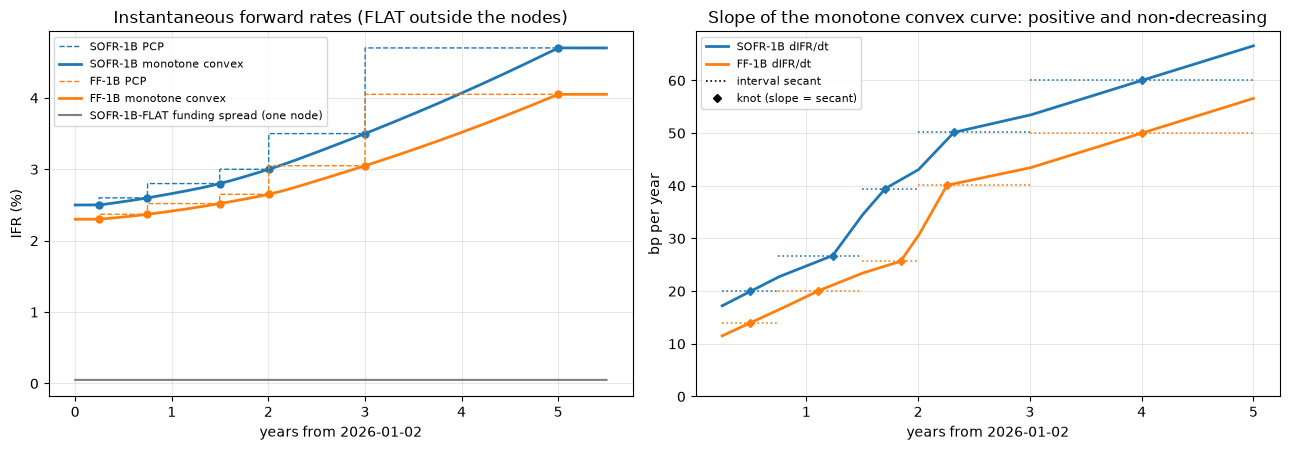

,curve,interval (yrs),secant (bp/yr),monotone,within node values,shape
0,SOFR-1B,0.247 - 0.748,19.95,True,True,convex
1,SOFR-1B,0.748 - 1.496,26.74,True,True,convex
2,SOFR-1B,1.496 - 2.003,39.46,True,True,convex
3,SOFR-1B,2.003 - 3.000,50.14,True,True,convex
4,SOFR-1B,3.000 - 5.000,60.00,True,True,convex
5,FF-1B,0.247 - 0.748,13.96,True,True,convex
6,FF-1B,0.748 - 1.496,20.05,True,True,convex
7,FF-1B,1.496 - 2.003,25.65,True,True,convex
8,FF-1B,2.003 - 3.000,40.11,True,True,convex
9,FF-1B,3.000 - 5.000,50.00,True,True,convex


In [2]:
# IFR curves from both interpolators on the supplied data. The PV cells below build their own models.
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

VALUE_DATE = "2026-01-02"


def build_ifr_model(interpolation_method):
    methods = qfCreateModelBuildMethodCollection([
        qfCreateBuildMethod(kind, {**inputs, "INTERPOLATION METHOD": interpolation_method,
                                   "EXTRAPOLATION METHOD": "FLAT"})
        for kind, inputs in curve_inputs
    ])
    return qfCreateModel(VALUE_DATE, "YIELD_CURVE", data_collection, methods)


def ifr(model, index):
    return model.retrieve_model_component(index).state_data_interpolator


def interval_shapes(interp, label, points=2001):
    """Classify each node interval on a fine grid: monotone, inside the node values, convex/concave."""
    x, y = np.asarray(interp.axis1, float), np.asarray(interp.values, float)
    rows = []
    for i in range(len(x) - 1):
        f = np.array([interp.interpolate(v) for v in np.linspace(x[i], x[i + 1], points)])
        first, second = np.diff(f), np.diff(f, 2)
        tol = 1e-14
        convex, concave = np.all(second >= -tol), np.all(second <= tol)
        rows.append({
            "curve": label, "interval (yrs)": f"{x[i]:.3f} - {x[i + 1]:.3f}",
            "secant (bp/yr)": 1e4 * (y[i + 1] - y[i]) / (x[i + 1] - x[i]),
            "monotone": bool(np.all(first >= -tol) or np.all(first <= tol)),
            "within node values": bool(f.min() >= min(y[i], y[i + 1]) - tol and f.max() <= max(y[i], y[i + 1]) + tol),
            "shape": "linear" if convex and concave else "convex" if convex else "concave" if concave else "one inflection",
        })
    return rows


pcp_curves = build_ifr_model("PIECEWISE_CONSTANT_LEFT_CONTINUOUS")
mc_curves = build_ifr_model("MONOTONE_CONVEX")

t = np.linspace(0.0, 5.5, 2201)
fig, (ax_rate, ax_slope) = plt.subplots(1, 2, figsize=(13, 4.6))
for index, colour in [("SOFR-1B", "tab:blue"), ("FF-1B", "tab:orange")]:
    pcp, mc = ifr(pcp_curves, index), ifr(mc_curves, index)
    ax_rate.plot(t, [100 * pcp.interpolate(v) for v in t], color=colour, ls="--", lw=1, label=f"{index} PCP")
    ax_rate.plot(t, [100 * mc.interpolate(v) for v in t], color=colour, lw=2, label=f"{index} monotone convex")
    ax_rate.plot(mc.axis1, 100 * np.asarray(mc.values), "o", color=colour, ms=5)
    # Derivative by central differences inside the node range, against each interval's secant.
    tt = np.linspace(mc.axis1[0], mc.axis1[-1], 4001)
    ax_slope.plot(tt, 1e4 * np.gradient([mc.interpolate(v) for v in tt], tt), color=colour, lw=2,
                  label=f"{index} dIFR/dt")
    secants = np.diff(mc.values) / np.diff(mc.axis1)
    ax_slope.hlines(1e4 * secants, mc.axis1[:-1], mc.axis1[1:], color=colour, ls=":", lw=1.2)
    ax_slope.plot(mc.knots_, 1e4 * mc.knot_slopes_, "D", color=colour, ms=4)
ax_rate.plot(t, [100 * ifr(mc_curves, "SOFR-1B-FLAT").interpolate(v) for v in t], color="grey", lw=1.5,
             label="SOFR-1B-FLAT funding spread (one node)")
ax_rate.set(title="Instantaneous forward rates (FLAT outside the nodes)", xlabel="years from 2026-01-02",
            ylabel="IFR (%)")
ax_rate.legend(fontsize=8)
ax_slope.set(title="Slope of the monotone convex curve: positive and non-decreasing",
             xlabel="years from 2026-01-02", ylabel="bp per year")
ax_slope.plot([], [], "k:", lw=1.2, label="interval secant")
ax_slope.plot([], [], "kD", ms=4, label="knot (slope = secant)")
ax_slope.legend(fontsize=8)
ax_slope.set_ylim(bottom=0)
for ax in (ax_rate, ax_slope):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

funding = ifr(mc_curves, "SOFR-1B-FLAT")
assert all(funding.interpolate(v) == 0.0005 for v in [0.0, 1.0, 1.00547945, 5.0, 30.0])
assert np.isclose(funding.integrate(0.0, 2.0), 2 * 0.0005, rtol=0, atol=1e-18)
display(pd.DataFrame(interval_shapes(ifr(mc_curves, "SOFR-1B"), "SOFR-1B")
                     + interval_shapes(ifr(mc_curves, "FF-1B"), "FF-1B")).round(2))

**Method.** `Interpolator1DMonotoneConvex` in `fixedincomelib/utilities/numerics.py` is a
shape-preserving C¹ quadratic spline through the IFR nodes $(t_i, f_i)$, FLAT outside $[t_0, t_n]$.
As in Hagan and West's monotone convex method, each node interval holds one quadratic, or two
quadratics joined at one extra breakpoint. The difference is the input: Hagan–West start from
discrete forwards (interval averages), while here the supplied numbers are point values of the IFR,
so the curve has to pass through them. Every step is local: a node only affects its neighbouring
intervals.

1. *Node slopes.* With secants $d_i = (f_i - f_{i-1})/h_i$ and $h_i = t_i - t_{i-1}$, an interior node
   gets the three-point (parabolic) slope $s_i = (h_{i+1} d_i + h_i d_{i+1})/(h_i + h_{i+1})$, capped at
   $2\min(|d_i|, |d_{i+1}|)$, and $s_i = 0$ if $d_i d_{i+1} \le 0$ (a local extremum). An end node takes the
   slope that makes the end interval a single quadratic, $s_0 = 2d_1 - s_1$ and $s_n = 2d_n - s_{n-1}$; the cap
   keeps it on the same side of zero as the end secant. Each $s_i$ therefore lies between its two neighbouring
   secants and has their sign.
2. *One knot per interval.* On $[t_{i-1}, t_i]$ the slope of any C¹ interpolant must equal $d_i$ somewhere
   (mean value theorem). The knot $\xi_i = t_{i-1} + h_i (s_i - d_i)/(s_i - s_{i-1})$ is placed there,
   and the slope is linear on each side of it: $s_{i-1} \to d_i \to s_i$. Each side is a quadratic, the two
   sides meet with equal value and slope, and their rises add up to $h_i d_i$, so the curve lands on $f_i$.
   `integrate` uses the exact cubic antiderivative, so discount factors carry no quadrature error.

**Why it is monotone and convex.** If the nodes are increasing with increasing secants
($0 < d_1 < d_2 < \dots < d_n$), step 1 gives $0 \le s_{i-1} < d_i < s_i$ on every interval. The slope then
rises through $s_{i-1}, d_i, s_i$: a rising slope means convex, a non-negative slope means increasing, so
the curve also stays between $f_{i-1}$ and $f_i$. The slopes match at the nodes, so this holds on the whole
range $[t_0, t_n]$, not only inside each interval. The supplied secants are 20, 27, 39, 50, 60 bp/yr for SOFR
and 14, 20, 26, 40, 50 bp/yr for Fed Funds, so both curves are of this kind. The right panel shows the slope
rising piecewise linearly and crossing each interval's secant at the knot; the table checks every interval on
a fine grid. Decreasing data with secants rising towards zero is the mirror case.

**Data that cannot satisfy every condition.** Continuity and passing through the nodes are never given up;
monotonicity within each interval is kept for any data. What gives way depends on the data (section 8.3 shows
each case):

- *A local extremum* (hump or trough at a node). The slope there is set to 0, so neither neighbouring interval
  overshoots the node values. A C¹ curve cannot be convex on both sides of a peak, so the interval rising into
  a peak is concave: the curve bends the way the data bend.
- *Secants that turn* (data convex at one end of an interval and concave at the other). One inflection is
  unavoidable; the knot moves to the interval midpoint and holds it. The slope cap keeps the slope at the knot,
  $2d_i - (s_{i-1} + s_i)/2$, of the same sign as $d_i$, so the interval stays monotone.
- *Collinear nodes* (equal secants). A convex curve through three collinear points is straight between them,
  so the interval is linear and the knot sits on the node, leaving a convex kink there. Smoothness (C¹) is what
  gives way here, not monotonicity or convexity.
- *One node* gives a constant curve (the funding spread above); *two nodes* give a straight line.
  FLAT extrapolation meets the curve with a kink at $t_0$ and $t_n$, since a rising convex curve cannot flatten out.

In [3]:
# 1. FRA — piecewise constant
fra_pcp_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_pcp_model = qfCreateModel(
    fra_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_pcp_product = qfCreateProductFRA(
    effective_date=fra_pcp_convention['effective date'],
    term_or_termination_date=fra_pcp_convention['termination date'],
    projection_index=fra_pcp_convention['projection index'],
    fixed_rate=fra_pcp_convention['fixed rate'],
    notional=fra_pcp_convention['notional'],
    pay_or_rec=fra_pcp_convention['pay or receive'],
    accrual_basis=fra_pcp_convention['accrual basis'],
    business_day_convention=fra_pcp_convention['business day convention'],
    holiday_convention=fra_pcp_convention['holiday convention'],
)
fra_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_pcp_convention["funding index"],
    }),
])
fra_pcp_pv = qfCreateValueReport(fra_pcp_model, fra_pcp_product, fra_pcp_parameters, "PV")[0][1]
print("FRA | PCP PV:", fra_pcp_pv)


FRA | PCP PV: 2908.2866392379638


In [4]:
# 2. FRA — your interpolator
fra_student_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_student_model = qfCreateModel(
    fra_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_student_product = qfCreateProductFRA(
    effective_date=fra_student_convention['effective date'],
    term_or_termination_date=fra_student_convention['termination date'],
    projection_index=fra_student_convention['projection index'],
    fixed_rate=fra_student_convention['fixed rate'],
    notional=fra_student_convention['notional'],
    pay_or_rec=fra_student_convention['pay or receive'],
    accrual_basis=fra_student_convention['accrual basis'],
    business_day_convention=fra_student_convention['business day convention'],
    holiday_convention=fra_student_convention['holiday convention'],
)
fra_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_student_convention["funding index"],
    }),
])
fra_student_pv = qfCreateValueReport(fra_student_model, fra_student_product, fra_student_parameters, "PV")[0][1]
print("FRA | Student PV:", fra_student_pv)
print("Student minus PCP:", fra_student_pv - fra_pcp_pv)


FRA | Student PV: 3261.7155818210267
Student minus PCP: 353.42894258306296


In [5]:
# 3. RFR swap — piecewise constant
swap_pcp_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_pcp_model = qfCreateModel(
    swap_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_pcp_product = qfCreateProductRFRSwap(
    effective_date=swap_pcp_convention['effective date'],
    term_or_termination_date=swap_pcp_convention['termination date'],
    on_index=swap_pcp_convention['overnight index'],
    fixed_rate=swap_pcp_convention['fixed rate'],
    notional=swap_pcp_convention['notional'],
    pay_or_rec=swap_pcp_convention['pay or receive'],
    accrual_period=swap_pcp_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_pcp_convention['floating accrual period'],
    accrual_basis=swap_pcp_convention['accrual basis'],
    compounding_method=swap_pcp_convention['compounding method'],
    spread=swap_pcp_convention['floating spread'],
    payment_off_set=swap_pcp_convention['payment offset'],
    pay_business_day_convention=swap_pcp_convention['payment business day convention'],
    pay_holiday_convention=swap_pcp_convention['payment holiday convention'],
)
swap_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_pcp_convention["funding index"],
    }),
])
swap_pcp_pv = qfCreateValueReport(swap_pcp_model, swap_pcp_product, swap_pcp_parameters, "PV")[0][1]
print("RFR swap | PCP PV:", swap_pcp_pv)


RFR swap | PCP PV: 6222.517513070154


In [6]:
# 4. RFR swap — your interpolator
swap_student_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_student_model = qfCreateModel(
    swap_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_student_product = qfCreateProductRFRSwap(
    effective_date=swap_student_convention['effective date'],
    term_or_termination_date=swap_student_convention['termination date'],
    on_index=swap_student_convention['overnight index'],
    fixed_rate=swap_student_convention['fixed rate'],
    notional=swap_student_convention['notional'],
    pay_or_rec=swap_student_convention['pay or receive'],
    accrual_period=swap_student_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_student_convention['floating accrual period'],
    accrual_basis=swap_student_convention['accrual basis'],
    compounding_method=swap_student_convention['compounding method'],
    spread=swap_student_convention['floating spread'],
    payment_off_set=swap_student_convention['payment offset'],
    pay_business_day_convention=swap_student_convention['payment business day convention'],
    pay_holiday_convention=swap_student_convention['payment holiday convention'],
)
swap_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_student_convention["funding index"],
    }),
])
swap_student_pv = qfCreateValueReport(swap_student_model, swap_student_product, swap_student_parameters, "PV")[0][1]
print("RFR swap | Student PV:", swap_student_pv)
print("Student minus PCP:", swap_student_pv - swap_pcp_pv)


RFR swap | Student PV: 12844.059560239228
Student minus PCP: 6621.542047169074


In [7]:
# 5. Overnight basis swap — piecewise constant
basis_pcp_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_pcp_model = qfCreateModel(
    basis_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_pcp_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_pcp_convention['effective date'],
    term_or_termination_date=basis_pcp_convention['termination date'],
    on_index_leg_1=basis_pcp_convention['overnight index leg 1'],
    on_index_leg_2=basis_pcp_convention['overnight index leg 2'],
    spread_over_leg_1=basis_pcp_convention['spread over leg 1'],
    notional=basis_pcp_convention['notional'],
    pay_or_rec_leg_1=basis_pcp_convention['pay or receive leg 1'],
    accrual_period_1=basis_pcp_convention['accrual period leg 1'],
    accrual_period_2=basis_pcp_convention['accrual period leg 2'],
    accrual_basis=basis_pcp_convention['accrual basis'],
    compounding_method=basis_pcp_convention['compounding method'],
    payment_off_set=basis_pcp_convention['payment offset'],
    pay_business_day_convention=basis_pcp_convention['payment business day convention'],
    pay_holiday_convention=basis_pcp_convention['payment holiday convention'],
)
basis_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_pcp_convention["funding index"],
    }),
])
basis_pcp_pv = qfCreateValueReport(basis_pcp_model, basis_pcp_product, basis_pcp_parameters, "PV")[0][1]
print("Overnight basis swap | PCP PV:", basis_pcp_pv)


Overnight basis swap | PCP PV: 8351.348908181993


In [8]:
# 6. Overnight basis swap — your interpolator
basis_student_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_student_model = qfCreateModel(
    basis_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_student_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_student_convention['effective date'],
    term_or_termination_date=basis_student_convention['termination date'],
    on_index_leg_1=basis_student_convention['overnight index leg 1'],
    on_index_leg_2=basis_student_convention['overnight index leg 2'],
    spread_over_leg_1=basis_student_convention['spread over leg 1'],
    notional=basis_student_convention['notional'],
    pay_or_rec_leg_1=basis_student_convention['pay or receive leg 1'],
    accrual_period_1=basis_student_convention['accrual period leg 1'],
    accrual_period_2=basis_student_convention['accrual period leg 2'],
    accrual_basis=basis_student_convention['accrual basis'],
    compounding_method=basis_student_convention['compounding method'],
    payment_off_set=basis_student_convention['payment offset'],
    pay_business_day_convention=basis_student_convention['payment business day convention'],
    pay_holiday_convention=basis_student_convention['payment holiday convention'],
)
basis_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_student_convention["funding index"],
    }),
])
basis_student_pv = qfCreateValueReport(basis_student_model, basis_student_product, basis_student_parameters, "PV")[0][1]
print("Overnight basis swap | Student PV:", basis_student_pv)
print("Student minus PCP:", basis_student_pv - basis_pcp_pv)


Overnight basis swap | Student PV: 7623.3009384916
Student minus PCP: -728.0479696903931


In [9]:
# 7. PV comparison, with the average IFRs over each product's dates that drive the differences.
import QuantLib as ql
from fixedincomelib.date import Date, accrued

act360 = ql.Actual360()


def average_ifr(model, index, start, end):
    t0, t1 = accrued(model.value_date, Date(start)), accrued(model.value_date, Date(end))
    return ifr(model, index).integrate(t0, t1) / (t1 - t0)


windows = {
    "FRA": (fra_pcp_convention["effective date"], fra_pcp_convention["termination date"]),
    "RFR swap": (swap_pcp_convention["effective date"], swap_pcp_convention["termination date"]),
    "Overnight basis swap": (basis_pcp_convention["effective date"], basis_pcp_convention["termination date"]),
}
pvs = {"FRA": (fra_pcp_pv, fra_student_pv), "RFR swap": (swap_pcp_pv, swap_student_pv),
       "Overnight basis swap": (basis_pcp_pv, basis_student_pv)}
rows = []
for product, (start, end) in windows.items():
    pcp_pv, mc_pv = pvs[product]
    sofr = [average_ifr(m, "SOFR-1B", start, end) for m in (pcp_curves, mc_curves)]
    ff = [average_ifr(m, "FF-1B", start, end) for m in (pcp_curves, mc_curves)]
    rows.append({"product": product, "dates": f"{start} to {end}", "PCP PV": pcp_pv, "MC PV": mc_pv,
                 "MC - PCP": mc_pv - pcp_pv,
                 "avg SOFR PCP (%)": 100 * sofr[0], "avg SOFR MC (%)": 100 * sofr[1],
                 "avg SOFR-FF PCP (bp)": 1e4 * (sofr[0] - ff[0]), "avg SOFR-FF MC (bp)": 1e4 * (sofr[1] - ff[1])})
display(pd.DataFrame(rows).set_index("product").round(4))

# Compounded SOFR rate of each annual swap coupon, P(T_s) / P(T_e) - 1 over the ACT/360 accrual.
coupon_rows = []
for i in range(swap_pcp_product.floating_leg.num_cashflows()):
    cf = swap_pcp_product.floating_leg.cashflow(i)
    row = {"coupon": f"{cf.effective_date.ISO()} to {cf.termination_date.ISO()}"}
    for label, model in [("PCP", swap_pcp_model), ("MC", swap_student_model)]:
        growth = model.discount_factor("SOFR-1B", cf.effective_date) / model.discount_factor("SOFR-1B", cf.termination_date)
        row[f"{label} rate (%)"] = 100 * (growth - 1.0) / act360.yearFraction(cf.effective_date, cf.termination_date)
    coupon_rows.append(row)
display(pd.DataFrame(coupon_rows).round(4))

,dates,PCP PV,MC PV,MC - PCP,avg SOFR PCP (%),avg SOFR MC (%),avg SOFR-FF PCP (bp),avg SOFR-FF MC (bp)
product,,,,,,,,
FRA,2026-05-05 to 2026-11-05,2908.2866,3261.7156,353.4289,2.6370,2.5665,23.9239,22.0297
RFR swap,2026-04-02 to 2029-04-02,6222.5175,12844.0596,6621.5420,3.1892,2.9577,37.0393,32.3160
Overnight basis swap,2026-07-02 to 2028-07-03,8351.3489,7623.3009,-728.0480,2.9991,2.8344,33.3596,29.5021


,coupon,PCP rate (%),MC rate (%)
0,2026-04-02 to 2027-04-02,2.6990,2.6018
1,2027-04-02 to 2028-04-03,3.0772,2.9025
2,2028-04-03 to 2029-04-02,3.8091,3.3727


### 7. PV comparison

Both curves are FLAT at the same values before the first node and after the last, so the differences come from
inside the node range. `PIECEWISE_CONSTANT_LEFT_CONTINUOUS` gives every interval $(t_{i-1}, t_i]$ the IFR of its
right node, $f_i$. For these upward-sloping curves that is the highest value on the interval, while the monotone
convex curve stays between $f_{i-1}$ and $f_i$. So the PCP forwards are higher everywhere between the nodes, by
up to the full step between two nodes, and the monotone convex curve also gives slightly higher discount factors
(the funding curve is SOFR plus a constant 5 bp).

- **FRA** (receive 3.2% against SOFR, May to November 2026). The average SOFR IFR over the FRA period falls by
  about 7 bp (2.64% to 2.57%). Receiving fixed against a lower projected rate is worth about
  $N \tau \times 7\text{ bp} \times D_f \approx 1{,}000{,}000 \times 0.511 \times 0.0007 \times 0.98 \approx 352$,
  hence **+353**.
- **RFR swap** (receive 3.4% against compounded SOFR, three annual coupons). The coupon rates fall from
  2.70 / 3.08 / 3.81% to 2.60 / 2.90 / 3.37%. The last coupon moves most: PCP applies the 5-year node (4.7%)
  as soon as the curve passes the 3-year node, i.e. over the swap's final quarter, while the monotone convex
  curve only starts to rise from 3.5% there. The floating leg we pay falls by 6,283 and the fixed leg we receive
  gains 338 from the higher discount factors, hence **+6,622**; the par rate drops from 3.18% to 2.95%. It is the
  largest change because the swap is the longest product and reaches the steepest part of the curve.
- **Overnight basis swap** (receive SOFR + 10 bp, pay Fed Funds, quarterly, July 2026 to July 2028). Here the PV
  depends on the SOFR–FF basis, not on the level. The node bases are 20, 23, 28, 35, 45 and 65 bp, widening
  with maturity. PCP uses each interval's right-node basis, while the monotone convex basis moves gradually
  between nodes, so the average basis over the swap falls from 33.4 bp to 29.5 bp. Both legs lose value
  (SOFR leg −3,057, Fed Funds leg −2,329); receiving SOFR loses about 4 bp a year more on roughly two years of
  annuity, hence **−728**.

The PCP curve is a step function that jumps to the next node's value straight after each node, which over-weights
the later node; the monotone convex curve moves gradually between the nodes, with no overshoot.

### 8. Implementation notes and validation

`Interpolator1DMonotoneConvex` is the only library change (plus `matplotlib` in `requirements.txt` for the plots).
The constructor computes the node slopes, then per interval the knot, the slope and value at the knot, the two
curvatures and the cumulative integral up to each node. `interpolate` finds the interval with `searchsorted` and
evaluates one quadratic; `integrate` is the difference of an exact antiderivative (cubic within each piece, linear
in the FLAT regions, negative to the left of the first node). With one node both return the constant. The two
optional gradient methods are left as supplied.

The checks below are independent of the code they test: they use fine-grid differences, Gauss–Legendre
quadrature of `interpolate` (not `integrate`), and the discount-factor-only formulas for the three products.

In [10]:
# 8.1 Interpolator properties on the supplied data: node values, C1 at the nodes, monotone and convex on the whole
# node range, the integral against quadrature, exact reproduction of a quadratic, and the one- and two-node cases.
from numpy.polynomial.legendre import leggauss

gauss_x, gauss_w = leggauss(8)


def quadrature(interp, a, b, panels_per_year=400):
    """Composite 8-point Gauss-Legendre over [a, b], splitting at the nodes. Uses interpolate() only."""
    edges = np.unique(np.concatenate(([a, b], [x for x in interp.axis1 if a < x < b])))
    total = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        panels = max(1, int(np.ceil((hi - lo) * panels_per_year)))
        cuts = np.linspace(lo, hi, panels + 1)
        for p0, p1 in zip(cuts[:-1], cuts[1:]):
            mid, half = 0.5 * (p0 + p1), 0.5 * (p1 - p0)
            total += half * sum(w * interp.interpolate(mid + half * g) for g, w in zip(gauss_x, gauss_w))
    return total


for index in ["SOFR-1B", "FF-1B"]:
    mc = ifr(mc_curves, index)
    x, y = np.asarray(mc.axis1), np.asarray(mc.values)
    assert all(mc.interpolate(xi) == yi for xi, yi in zip(x, y))                      # passes through the nodes
    eps = 1e-6
    for xi in x[1:-1]:                                                                    # C1: equal one-sided slopes
        left = (mc.interpolate(xi) - mc.interpolate(xi - eps)) / eps
        right = (mc.interpolate(xi + eps) - mc.interpolate(xi)) / eps
        assert abs(left - right) < 1e-6, (index, xi, left, right)
    grid = np.linspace(x[0], x[-1], 20001)
    values = np.array([mc.interpolate(v) for v in grid])
    assert np.all(np.diff(values) > 0) and np.all(np.diff(values, 2) >= -1e-14)          # increasing and convex on [t_0, t_n]
    for a, b in [(0.0, 0.1), (0.0, 1.0), (0.3, 2.7), (1.2, 4.4), (0.0, 7.0), (4.9, 6.0)]:
        np.testing.assert_allclose(mc.integrate(a, b), quadrature(mc, a, b), rtol=1e-12)
    np.testing.assert_allclose(mc.integrate(0.0, 2.0) + mc.integrate(2.0, 5.5), mc.integrate(0.0, 5.5), rtol=1e-14)
    np.testing.assert_allclose(mc.integrate(1.0, 3.0), -mc.integrate(3.0, 1.0), rtol=1e-14)
    print(f"{index}: nodes exact, C1 at {len(x) - 2} interior nodes, increasing and convex on "
          f"[{x[0]:.3f}, {x[-1]:.3f}], integral(0, 7) = {mc.integrate(0.0, 7.0):.12f}")

# A quadratic is reproduced exactly: its three-point slopes are exact and every knot sits at the midpoint.
from fixedincomelib.utilities.numerics import Interpolator1DMonotoneConvex, ExtrapMethod
xs = np.array([0.25, 0.75, 1.5, 2.0, 3.0, 5.0])
quad = lambda v: 0.02 + 0.001 * v + 0.0008 * v ** 2
reproduced = Interpolator1DMonotoneConvex(xs, quad(xs), ExtrapMethod.FLAT)
probe = np.linspace(xs[0], xs[-1], 997)
assert np.max(np.abs([reproduced.interpolate(v) - quad(v) for v in probe])) < 1e-15
np.testing.assert_allclose(reproduced.integrate(0.25, 5.0),
                           0.02 * 4.75 + 0.0005 * (25 - 0.0625) + 0.0008 / 3 * (125 - 0.015625), rtol=1e-14)

# One node: constant; two nodes: the straight line.
one = Interpolator1DMonotoneConvex(np.array([1.0]), np.array([0.0005]), ExtrapMethod.FLAT)
assert one.interpolate(-3.0) == one.interpolate(1.0) == one.interpolate(40.0) == 0.0005
np.testing.assert_allclose(one.integrate(0.0, 2.5), 0.0005 * 2.5, rtol=1e-15)
two = Interpolator1DMonotoneConvex(np.array([1.0, 3.0]), np.array([0.02, 0.03]), ExtrapMethod.FLAT)
np.testing.assert_allclose([two.interpolate(v) for v in [0.0, 1.5, 2.0, 2.9, 9.0]],
                           [0.02, 0.0225, 0.025, 0.0295, 0.03], rtol=1e-14)
print("Quadratic reproduced to machine precision; one-node constant and two-node line confirmed.")

SOFR-1B: nodes exact, C1 at 4 interior nodes, increasing and convex on [0.247, 5.000], integral(0, 7) = 0.261661459597


FF-1B: nodes exact, C1 at 4 interior nodes, increasing and convex on [0.247, 5.000], integral(0, 7) = 0.228612334234
Quadratic reproduced to machine precision; one-node constant and two-node line confirmed.


In [11]:
# 8.2 The six PVs from discount factors built by quadrature of interpolate() and the closed forms
# FRA: N tau (K - F) D_f(T_e), F = (P(T_s) / P(T_e) - 1) / tau;  fixed leg: N K sum alpha_i D_f(T_i^p);
# overnight leg: N sum [(P(T_i^s) / P(T_i^e) - 1) + alpha_i s] D_f(T_i^p).
def quadrature_df(model, index, date):
    component = model.retrieve_model_component(index)
    df = np.exp(-quadrature(component.state_data_interpolator, 0.0, accrued(model.value_date, date)))
    reference = getattr(component.component_identifier, "reference_index", None)
    return df if reference is None else df * quadrature_df(model, reference, date)


def leg_pv(model, stream, funding, index=None, rate=0.0):
    """Fixed leg (index None, rate K) or overnight leg on `index` with spread `rate`."""
    pv = 0.0
    for i in range(stream.num_cashflows()):
        cf = stream.cashflow(i)
        alpha = act360.yearFraction(cf.effective_date, cf.termination_date)
        coupon = alpha * rate
        if index is not None:
            coupon += quadrature_df(model, index, cf.effective_date) / quadrature_df(model, index, cf.termination_date) - 1.0
        pv += stream.notional * coupon * quadrature_df(model, funding, cf.payment_date)
    return pv


def fra_formula(model, product, convention):
    tau = product.accrued
    forward = (quadrature_df(model, convention["projection index"], product.effective_date)
               / quadrature_df(model, convention["projection index"], product.termination_date) - 1.0) / tau
    return convention["notional"] * tau * (convention["fixed rate"] - forward) * quadrature_df(
        model, convention["funding index"], product.payment_date)


def swap_formula(model, product, convention):
    funding = convention["funding index"]
    return (leg_pv(model, product.fixed_leg, funding, rate=convention["fixed rate"])
            - leg_pv(model, product.floating_leg, funding, index=convention["overnight index"]))


def basis_formula(model, product, convention):
    funding = convention["funding index"]
    return (leg_pv(model, product.floating_leg_1, funding, index=convention["overnight index leg 1"],
                   rate=convention["spread over leg 1"])
            - leg_pv(model, product.floating_leg_2, funding, index=convention["overnight index leg 2"]))


cases = [
    ("FRA", "PCP", fra_formula, fra_pcp_model, fra_pcp_product, fra_pcp_convention, fra_pcp_pv),
    ("FRA", "MC", fra_formula, fra_student_model, fra_student_product, fra_student_convention, fra_student_pv),
    ("RFR swap", "PCP", swap_formula, swap_pcp_model, swap_pcp_product, swap_pcp_convention, swap_pcp_pv),
    ("RFR swap", "MC", swap_formula, swap_student_model, swap_student_product, swap_student_convention, swap_student_pv),
    ("Basis swap", "PCP", basis_formula, basis_pcp_model, basis_pcp_product, basis_pcp_convention, basis_pcp_pv),
    ("Basis swap", "MC", basis_formula, basis_student_model, basis_student_product, basis_student_convention, basis_student_pv),
]
check_rows = []
for product, method, formula, model, instrument, convention, engine_pv in cases:
    independent = formula(model, instrument, convention)
    np.testing.assert_allclose(engine_pv, independent, rtol=1e-9, atol=1e-6)
    check_rows.append({"product": product, "interpolation": method, "engine PV": engine_pv,
                       "quadrature + formula PV": independent, "difference": engine_pv - independent})
display(pd.DataFrame(check_rows))

,product,interpolation,engine PV,quadrature + formula PV,difference
0,FRA,PCP,2908.286639,2908.286639,4.547474e-13
1,FRA,MC,3261.715582,3261.715582,1.818989e-12
2,RFR swap,PCP,6222.517513,6222.517513,-4.496542e-09
3,RFR swap,MC,12844.059560,12844.059560,3.536115e-09
4,Basis swap,PCP,8351.348908,8351.348908,-4.831236e-09
5,Basis swap,MC,7623.300938,7623.300938,-9.458745e-11


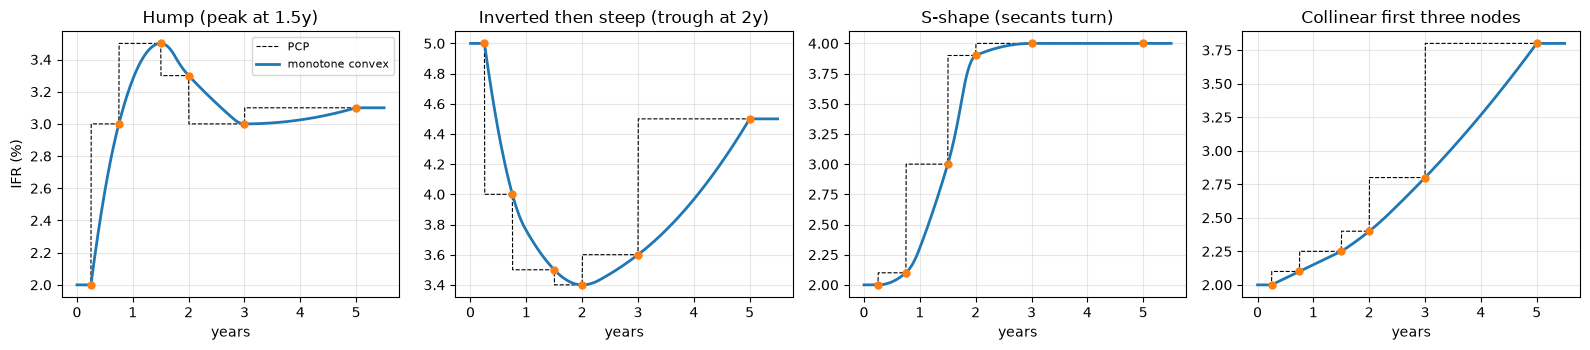

,curve,interval (yrs),secant (bp/yr),monotone,within node values,shape
0,Hump (peak at 1.5y),0.250 - 0.750,200.00,True,True,concave
1,Hump (peak at 1.5y),0.750 - 1.500,66.67,True,True,concave
2,Hump (peak at 1.5y),1.500 - 2.000,-40.00,True,True,one inflection
3,Hump (peak at 1.5y),2.000 - 3.000,-30.00,True,True,convex
4,Hump (peak at 1.5y),3.000 - 5.000,5.00,True,True,convex
5,Inverted then steep (trough at 2y),0.250 - 0.750,-200.00,True,True,convex
6,Inverted then steep (trough at 2y),0.750 - 1.500,-66.67,True,True,convex
7,Inverted then steep (trough at 2y),1.500 - 2.000,-20.00,True,True,convex
8,Inverted then steep (trough at 2y),2.000 - 3.000,20.00,True,True,convex
9,Inverted then steep (trough at 2y),3.000 - 5.000,45.00,True,True,convex


In [12]:
# 8.3 Data that cannot be both monotone and convex everywhere: what the interpolator does instead.
from fixedincomelib.utilities.numerics import Interpolator1DPCP

nodes = np.array([0.25, 0.75, 1.5, 2.0, 3.0, 5.0])
cases = {
    "Hump (peak at 1.5y)": [0.020, 0.030, 0.035, 0.033, 0.030, 0.031],
    "Inverted then steep (trough at 2y)": [0.050, 0.040, 0.035, 0.034, 0.036, 0.045],
    "S-shape (secants turn)": [0.020, 0.021, 0.030, 0.039, 0.040, 0.040],
    "Collinear first three nodes": [0.020, 0.021, 0.0225, 0.024, 0.028, 0.038],
}
fig, axes = plt.subplots(1, len(cases), figsize=(16, 3.6))
shape_rows = []
for ax, (label, values) in zip(axes, cases.items()):
    values = np.array(values)
    mc = Interpolator1DMonotoneConvex(nodes, values, ExtrapMethod.FLAT)
    pcp = Interpolator1DPCP(nodes, values, ExtrapMethod.FLAT)
    tt = np.linspace(0.0, 5.5, 1101)
    ax.plot(tt, [100 * pcp.interpolate(v) for v in tt], "k--", lw=0.8, label="PCP")
    ax.plot(tt, [100 * mc.interpolate(v) for v in tt], lw=2, label="monotone convex")
    ax.plot(nodes, 100 * values, "o", ms=5)
    ax.set(title=label, xlabel="years")
    ax.grid(alpha=0.3)
    rows = interval_shapes(mc, label)
    assert all(r["monotone"] and r["within node values"] for r in rows)   # never overshoots, in any case
    assert all(mc.interpolate(x) == y for x, y in zip(nodes, values))
    shape_rows += rows
axes[0].set_ylabel("IFR (%)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
display(pd.DataFrame(shape_rows).round(2))

Every interval stays monotone and inside its two node values for all four data sets, and the curve still passes
through every node. Convexity gives way only where the data force it:

- *Hump.* The data are concave up to the peak, so the intervals rising into it are concave. The interval just after
  the peak holds the single inflection, where the data turn convex again towards the trough at 3y; from there the
  curve is convex.
- *Inverted then steep.* A trough is compatible with convexity: the slope is 0 at the trough and the curve is
  convex on every interval, decreasing before 2y and increasing after.
- *S-shape.* The inflection sits in the 1.5y–2y interval, where the secants stop rising; after it the curve is
  concave and then flat.
- *Collinear start.* The first two intervals are one straight line; the curve then has a convex kink at the 1.5y
  node (slope 20 bp/yr on the left, higher on the right) and is convex afterwards. C¹ is what gives way here.